# 02 · 核心检验：功效分析、z 检验、置信区间与上线决策

**本 notebook 的学习目标**
1. 用**功效分析**回答"实验需要多少样本 / 跑多少天"，并评估本实验能检测到多小的效果（MDE）。
2. 用**双比例 z 检验**和**卡方检验**判断新页面的转化率是否与旧页面不同，并理解两者等价。
3. 用**置信区间**描述效果的大小与不确定性（比 p 值更有业务价值）。
4. 用 **Bootstrap** 和**置换检验**这两种不依赖正态近似的方法交叉验证结论。
5. 结合**统计显著性**与**业务显著性**给出上线 / 不上线建议。

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

sys.path.insert(0, str(Path("..", "src").resolve()))
from abtest import (load_raw, clean_ab_data, sample_size_per_group, power_two_proportions,
                    minimum_detectable_effect, two_proportion_ztest, chi2_independence,
                    bootstrap_diff_binary, permutation_test_binary)
from abtest.plotting import set_style, CONTROL, TREATMENT, ACCENT, MUTED

set_style()
FIG = Path("..", "reports", "figures")
df = clean_ab_data(*load_raw(), verbose=False)
summary = df.groupby("group").converted.agg(conversions="sum", users="count", rate="mean")
summary

,conversions,users,rate
group,,,
control,17489,145274,0.120386
treatment,17264,145310,0.118808


## 1. 写下假设（实验开始前就该确定）

- **指标**：用户层面转化率 $p = \dfrac{\text{转化用户数}}{\text{用户数}}$
- **原假设** $H_0$：$p_{new} = p_{old}$（新页面没有效果）
- **备择假设** $H_1$：$p_{new} \neq p_{old}$（双侧）
- **显著性水平** $\alpha = 0.05$：当 $H_0$ 为真时，我们愿意承担 5% 的概率误判"有效果"（第一类错误，假阳性）。
- **统计功效** $1-\beta = 0.8$：当真实效果等于 MDE 时，我们有 80% 的概率检测出来（$\beta$ 为第二类错误，假阴性）。

> **为什么用双侧？** 新页面也可能让转化**变差**，我们同样需要知道。单侧检验只在"变差和没变化对决策完全一样"且**事先**确定时才合理，事后改成单侧是 p-hacking。

## 2. 功效分析与样本量（Power Analysis）

### 概念
样本量由四个量共同决定：

| 输入 | 含义 | 对样本量的影响 |
|---|---|---|
| 基线转化率 $p_1$ | 旧页面的转化率（这里约 12%） | **绝对** MDE 固定时，越接近 50% 方差越大、样本越多；**相对** MDE 固定时，基线越低需要的样本越多 |
| 最小可检测效应 MDE $\delta$ | 业务上"值得检测"的最小提升 | **样本量 ∝ 1/δ²**，MDE 减半，样本量×4 |
| 显著性水平 $\alpha$ | 假阳性率 | α 越小需要越多样本 |
| 功效 $1-\beta$ | 真阳性率 | 功效越高需要越多样本 |

### 公式（每组样本量，两组等量）
$$n = \frac{\left(z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)} + z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)}\right)^2}{\delta^2}, \quad p_2 = p_1+\delta,\ \bar p = \frac{p_1+p_2}{2}$$

直觉：分子是"噪声"（标准误中的方差部分），分母是"信号"的平方。信号越小、噪声越大，就需要越多样本才能把信号从噪声里分辨出来。

In [2]:
p_base = summary.loc["control", "rate"]
daily_users = len(df) / df.date.nunique()

rows = []
for rel in [0.01, 0.02, 0.05, 0.10]:
    mde = p_base * rel
    n = sample_size_per_group(p_base, mde)
    rows.append({"相对提升 MDE": f"{rel:.0%}", "绝对提升 MDE": f"{mde:.4f}",
                 "每组样本量": f"{n:,}", "总样本量": f"{2*n:,}",
                 "所需天数(按本实验流量)": f"{2*n/daily_users:.1f}"})
pd.DataFrame(rows)

,相对提升 MDE,绝对提升 MDE,每组样本量,总样本量,所需天数(按本实验流量)
0,1%,0.0012,"1,151,917","2,303,834",182.4
1,2%,0.0024,"289,213","578,426",45.8
2,5%,0.0060,"46,864","93,728",7.4
3,10%,0.0120,"11,960","23,920",1.9


**解读**：本实验日均约 1.26 万用户。
- 想检测 **5% 的相对提升**（12.0% → 12.6%），每组需要约 4.7 万用户，大约 7–8 天就够。
- 想检测 **1% 的相对提升**，每组需要约 115 万用户，要跑半年，不现实。

这就是功效分析的业务价值：**在实验之前**和业务方对齐"我们能检测到多小的效果"，避免跑一个注定得不出结论的实验。

> 实践中，还建议至少跑满 **1–2 个完整的周**，以覆盖周内周期（工作日 vs 周末用户行为不同），即使样本量提前达标。

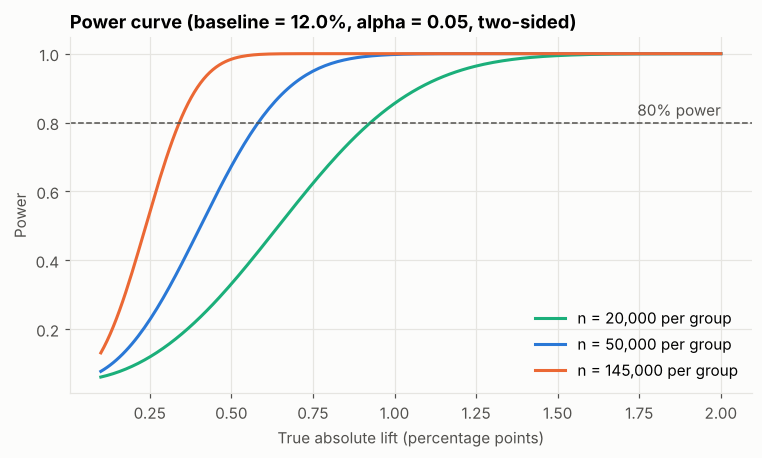

In [3]:
mdes = np.linspace(0.001, 0.02, 200)
fig, ax = plt.subplots()
for n, c in [(20_000, ACCENT), (50_000, CONTROL), (145_000, TREATMENT)]:
    ax.plot(mdes * 100, [power_two_proportions(p_base, d, n) for d in mdes], color=c,
            label=f"n = {n:,} per group")
ax.axhline(0.8, color=MUTED, ls="--", lw=1)
ax.text(2.0, 0.82, "80% power", ha="right", color=MUTED)
ax.set_xlabel("True absolute lift (percentage points)")
ax.set_ylabel("Power")
ax.set_title(f"Power curve (baseline = {p_base:.1%}, alpha = 0.05, two-sided)")
ax.legend(loc="lower right")
plt.savefig(FIG / "02_power_curve.png")
plt.show()

### 本实验实际能检测到多小的效果？
实验已经结束，我们反过来问：在每组约 14.5 万用户的情况下，**80% 功效下的 MDE 是多少？**

In [4]:
n_c = int(summary.loc["control", "users"])
mde_achieved = minimum_detectable_effect(p_base, n_c)
print(f"MDE (绝对) = {mde_achieved:.4f}  ->  约 {mde_achieved*100:.2f} 个百分点")
print(f"MDE (相对) = {mde_achieved/p_base:.1%}")

MDE (绝对) = 0.0034  ->  约 0.34 个百分点
MDE (相对) = 2.8%


**解读**：本实验能以 80% 的功效检测出约 **0.34 个百分点（相对 2.8%）** 的变化。也就是说，如果真实效果有 0.34pp 那么大，我们漏掉它的概率只有 20%。

但要注意两点：
- MDE 描述的是**实验的灵敏度**，不是效果的估计。"不显著 + MDE 小"不能直接推出"效果小于 MDE"，要说明效果有多大，还得看下一节的**置信区间**。
- 和第 2 节的表对照：相对 2.8% 的 MDE **大于** 2% 的相对提升。所以如果业务门槛是 2%，这个实验在设计上**功效不足**（检测 2% 需要每组约 29 万人）。本实验的结论之所以仍然站得住，是因为点估计是负的，置信区间上界远低于 2%，而不是因为功效充足。

> ⚠️ **不要计算"事后功效（observed / post-hoc power）"**：用观测到的效应量去算功效，它只是 p 值的一个单调变换，不提供新信息。正确的做法是报告**设计时的 MDE** 和**效果的置信区间**。

## 3. 双比例 z 检验（Two-proportion z-test）

### 前提假设
1. **随机分组**：两组可比（已在 01 验证）。
2. **独立性**：每个用户是独立观测，且两组之间互不影响（无网络效应 / 溢出效应，即 SUTVA）。
3. **大样本**：$np$ 与 $n(1-p)$ 都远大于 10（这里约 1.7 万和 12.8 万），根据中心极限定理，样本比例近似服从正态分布。

### 检验统计量
在 $H_0$ 下两组转化率相同，所以用**合并比例（pooled）** 估计共同的方差：
$$\hat p = \frac{x_c+x_t}{n_c+n_t}, \qquad z = \frac{\hat p_t - \hat p_c}{\sqrt{\hat p(1-\hat p)\left(\frac{1}{n_c}+\frac{1}{n_t}\right)}}$$

p 值 = 在 $H_0$ 成立的前提下，观察到至少这么极端的 $|z|$ 的概率 $= 2\,(1-\Phi(|z|))$。

In [5]:
x_c, n_c = summary.loc["control", ["conversions", "users"]].astype(int)
x_t, n_t = summary.loc["treatment", ["conversions", "users"]].astype(int)

res = two_proportion_ztest(x_c, n_c, x_t, n_t)
print(f"对照组转化率  p_c = {res.p_control:.4%}")
print(f"实验组转化率  p_t = {res.p_treatment:.4%}")
print(f"绝对差        p_t - p_c = {res.abs_diff:+.4%}")
print(f"相对提升      lift = {res.rel_lift:+.2%}")
print(f"z = {res.z:.3f},  p-value = {res.p_value:.4f}")

# 与 statsmodels 交叉验证
z_sm, p_sm = proportions_ztest([x_t, x_c], [n_t, n_c])
print(f"statsmodels:  z = {z_sm:.3f},  p-value = {p_sm:.4f}")

对照组转化率  p_c = 12.0386%
实验组转化率  p_t = 11.8808%
绝对差        p_t - p_c = -0.1578%
相对提升      lift = -1.31%
z = -1.311,  p-value = 0.1899
statsmodels:  z = -1.311,  p-value = 0.1899


**解读**：
- 新页面的转化率（11.88%）反而比旧页面（12.04%）**低 0.16 个百分点**，相对低 1.3%。
- p = 0.19 > 0.05，**不能拒绝 $H_0$**：观察到的差异完全可能是随机波动。

### ❗ p 值的正确理解（面试高频）
- ✅ p = 0.19 表示：**如果**新旧页面真的没差别，我们有 19% 的概率看到至少这么大的差异。
- ❌ 不是"新页面无效的概率是 19%"，也不是"$H_0$ 为真的概率"。
- ❌ "不显著"≠"证明没有差别"。不显著只说明**证据不足**；要说"没有重要差别"，需要看置信区间是否落在业务可接受的范围内。

## 4. 卡方独立性检验：另一种视角，同一个答案

把数据写成 2×2 列联表（组别 × 是否转化），检验"转化与组别是否独立"。对于 2×2 表（不做 Yates 连续性校正），**$\chi^2 = z^2$**，两者 p 值完全相同。

In [6]:
chi2, p_chi, dof = chi2_independence(x_c, n_c, x_t, n_t)
print(f"chi2 = {chi2:.4f}  (z^2 = {res.z**2:.4f}),  dof = {dof},  p = {p_chi:.4f}")

chi2 = 1.7185  (z^2 = 1.7185),  dof = 1,  p = 0.1899


**什么时候用哪个？** z 检验只适用于两组比较，但能直接给出差值和方向，并可以做单侧检验；卡方检验可以推广到多组（A/B/C/D）或多类别结果。

## 5. 置信区间：效果有多大、有多不确定

### 绝对差的 95% CI（Wald，非合并标准误）
$$(\hat p_t - \hat p_c) \pm z_{0.975}\sqrt{\frac{\hat p_c(1-\hat p_c)}{n_c}+\frac{\hat p_t(1-\hat p_t)}{n_t}}$$

为什么这里**不**用合并比例？因为估计区间时我们不再假设 $H_0$ 成立，两组各有自己的方差。

### 相对提升的 95% CI（Delta 方法）
业务方更习惯听"提升了百分之几"。相对提升 $\frac{p_t}{p_c}-1$ 是比值，不能直接把绝对差的 CI 除以 $p_c$（因为 $p_c$ 本身也有误差）。我们对 $\log(p_t/p_c)$ 用 Delta 方法：
$$\operatorname{Var}\left[\log\frac{\hat p_t}{\hat p_c}\right] \approx \frac{1-p_t}{n_t p_t} + \frac{1-p_c}{n_c p_c}$$
求出对数尺度的区间后再取指数、减 1。

In [7]:
print(f"绝对差 95% CI: [{res.ci_abs[0]:+.4%}, {res.ci_abs[1]:+.4%}]")
print(f"相对提升 95% CI: [{res.ci_rel[0]:+.2%}, {res.ci_rel[1]:+.2%}]")

绝对差 95% CI: [-0.3938%, +0.0781%]
相对提升 95% CI: [-3.24%, +0.66%]


**解读**：
- 区间 **[−0.39, +0.08] 个百分点** 包含 0 → 与"不显著"一致。（严格来说，"CI 包含 0 ⇔ 双侧 p > 0.05"只在两者用同一个标准误时成立；这里检验用合并 SE、CI 用非合并 SE，两者几乎相同，只有 p 值非常接近 0.05 时才可能不一致。）
- 更重要的是：区间的**上界只有 +0.08 个百分点（相对 +0.66%）**。也就是说，即使新页面有正面效果，最乐观的估计也只有约 0.66% 的相对提升。
- 如果业务方认为"至少要有 2% 的相对提升才值得投入上线和维护成本"，那么这个区间已经**排除了**有业务价值的正面效果。

> 💡 CI 的正确理解：如果重复实验很多次，按同样方法构造的区间有 95% 会覆盖真实差值。不是"真实差值有 95% 的概率在这个区间里"（那是贝叶斯可信区间的说法）。

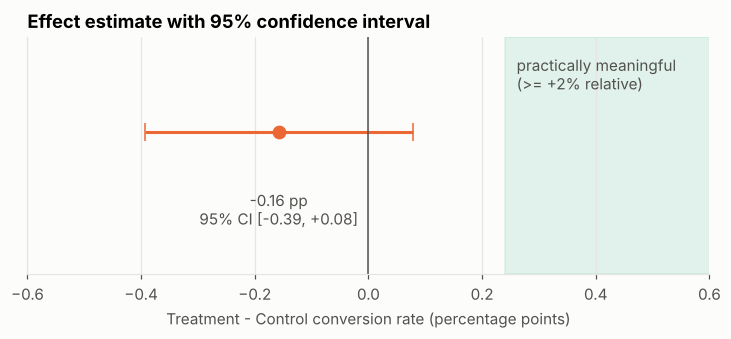

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
lo, hi = np.array(res.ci_abs) * 100
ax.errorbar(res.abs_diff * 100, 0, xerr=[[res.abs_diff * 100 - lo], [hi - res.abs_diff * 100]],
            fmt="o", color=TREATMENT, ms=8, capsize=6, lw=2)
ax.axvline(0, color=MUTED, lw=1)
practical = 0.02 * p_base * 100
ax.axvspan(practical, 1.0, color=ACCENT, alpha=0.12)
ax.text(practical + 0.02, 0.32, "practically meaningful\n(>= +2% relative)", color=MUTED, va="top")
ax.text(res.abs_diff * 100, -0.25, f"{res.abs_diff*100:+.2f} pp\n95% CI [{lo:+.2f}, {hi:+.2f}]",
        ha="center", va="top", color=MUTED)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.6, 0.4)
ax.set_yticks([])
ax.set_xlabel("Treatment - Control conversion rate (percentage points)")
ax.set_title("Effect estimate with 95% confidence interval")
plt.savefig(FIG / "02_effect_ci.png")
plt.show()

## 6. 单侧检验：如果预先假设"新页面更好"

原始 Udacity 课题把假设写成单侧：$H_1: p_{new} > p_{old}$。我们也算一下，用来理解单侧与双侧的区别：

In [9]:
res_one = two_proportion_ztest(x_c, n_c, x_t, n_t, alternative="larger")
print(f"单侧 (H1: p_t > p_c) p-value = {res_one.p_value:.4f}")

单侧 (H1: p_t > p_c) p-value = 0.9051


单侧 p ≈ 0.905，因为观察到的方向（新页面更差）与备择假设相反。结论一样：没有证据表明新页面更好。

## 7. 稳健性检查：不依赖正态近似的方法

z 检验依赖中心极限定理。样本量这么大时近似非常好，但用**重抽样方法**验证一下可以让结论更有说服力，也是面试常问的"你如何确认结果稳健？"

### 7.1 Bootstrap 置信区间
**思想**：把样本当作总体的替身，从每组中**有放回**地重抽同样大小的样本，计算差值；重复上万次，得到差值的经验分布，取 2.5% 与 97.5% 分位数作为 CI（百分位法）。

**实现技巧**：对 0/1 数据，"有放回抽 n 个再求和"在分布上**完全等价**于从 $\text{Binomial}(n, \hat p)$ 抽一个数，所以不必真的生成 14.5 万 × 10 万的大矩阵。

### 7.2 置换检验（Permutation test）
**思想**：如果 $H_0$ 为真，"组别标签"是可以随便交换的。把所有用户的标签随机打乱，重新计算差值；重复很多次，得到 $H_0$ 下差值的分布。p 值 = 打乱后差值至少和观测值一样极端的比例。

打乱标签后实验组里的转化人数服从**超几何分布**，同样可以直接抽样。

Bootstrap 95% CI: [-0.3939%, +0.0775%]   (z 检验: [-0.3938%, +0.0781%])
Permutation p-value: 0.1907   (z 检验: 0.1899)


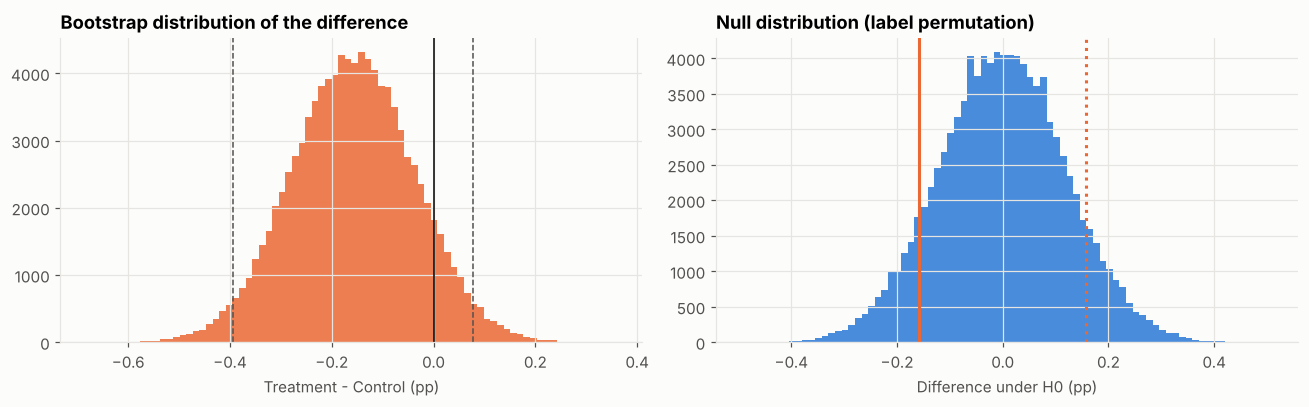

In [10]:
boot = bootstrap_diff_binary(x_c, n_c, x_t, n_t, n_boot=100_000)
perm = permutation_test_binary(x_c, n_c, x_t, n_t, n_perm=100_000)
print(f"Bootstrap 95% CI: [{boot['ci'][0]:+.4%}, {boot['ci'][1]:+.4%}]   (z 检验: [{res.ci_abs[0]:+.4%}, {res.ci_abs[1]:+.4%}])")
print(f"Permutation p-value: {perm['p_value']:.4f}   (z 检验: {res.p_value:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(boot["samples"] * 100, bins=80, color=TREATMENT, alpha=0.85)
for v in boot["ci"]:
    axes[0].axvline(v * 100, color=MUTED, ls="--", lw=1)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Bootstrap distribution of the difference")
axes[0].set_xlabel("Treatment - Control (pp)")
axes[1].hist(perm["samples"] * 100, bins=80, color=CONTROL, alpha=0.85)
axes[1].axvline(perm["observed"] * 100, color=TREATMENT, lw=2)
axes[1].axvline(-perm["observed"] * 100, color=TREATMENT, lw=2, ls=":")
axes[1].set_title("Null distribution (label permutation)")
axes[1].set_xlabel("Difference under H0 (pp)")
plt.tight_layout()
plt.savefig(FIG / "02_bootstrap_permutation.png")
plt.show()

**解读**：Bootstrap CI 与 z 检验的 CI 几乎一致，置换检验的 p 值也与 z 检验非常接近。三种方法结论一致 → 结论稳健。

当数据**偏态严重**（如人均收入）、样本**较小**、或指标是**比率 / 分位数**等没有简单方差公式的统计量时，Bootstrap 的优势才真正体现。

## 8. 上线决策

决策时同时看两件事：**统计显著性**（差异是否可能来自噪声）和**业务显著性**（差异是否大到值得行动）。

|  | 业务上有意义 | 业务上没意义 |
|---|---|---|
| **统计显著** | ✅ 上线 | 🤔 效果真实但太小，看成本 |
| **统计不显著** | 🔁 样本不够，考虑延长实验 | ❌ 不上线（**本实验**） |

### 结论
1. 新页面转化率 **11.88% vs 旧页面 12.04%**，差值 −0.16 个百分点，95% CI [−0.39, +0.08]，p = 0.19，**不显著**。
2. CI 上界仅 +0.66% 相对提升，远低于假设的 2% 业务门槛 → 即使有正面效果，也**小到没有业务价值**。注意这个论证靠的是**置信区间**：实验的 MDE（相对 2.8%）其实大于 2% 的门槛，单靠功效不足以下这个结论。
3. 数据质量检查（SRM、协变量平衡、每日趋势）全部通过，结论可信。

**建议：不上线新页面，保留旧页面。** 不建议延长实验，因为现有样本已足够排除有意义的提升。可以把资源投入到其他假设（如重新设计新页面的关键元素），并在下一次实验前先做功效分析。

进阶分析（CUPED 方差缩减、分国家分析与多重比较、偷看问题）见 → `03_advanced_methods.ipynb`。

### 🧠 自测题
1. 如果 p = 0.03，但相对提升 CI 是 [+0.1%, +0.8%]，你建议上线吗？（答：统计显著但效果很小，要权衡上线成本、维护成本；通常不值得，或者作为低优先级。）
2. 为什么 z 检验用合并比例而 CI 用非合并比例？（答：检验在 $H_0$ 下计算，$H_0$ 假设两组比例相同；CI 是估计，不假设 $H_0$。）
3. 样本量公式里 MDE 从 1% 降到 0.5%，样本量变成多少倍？（答：约 4 倍。）